In [ ]:
from datasets import load_dataset

dataset = load_dataset('lukebarousse/data_jobs')

df = dataset['train'].to_pandas()

README.md:   0%|          | 0.00/3.25k [00:00<?, ?B/s]

data_jobs.csv: reconstructing file:   0%|          |  0.00B /  231MB            

data_jobs.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/785741 [00:00<?, ? examples/s]

In [ ]:
df.describe()

,salary_year_avg,salary_hour_avg
count,22003.000000,10662.000000
mean,123286.274072,47.016598
std,48312.449482,21.890738
min,15000.000000,8.000000
25%,90000.000000,27.500000
50%,115000.000000,45.980000
75%,150000.000000,61.159996
max,960000.000000,391.000000


In [ ]:
import pandas as pd

In [ ]:
df['job_posted_date']=pd.to_datetime(df.job_posted_date)

In [ ]:
df['job_posted_month'] = df.job_posted_date.dt.month

In [ ]:
df.describe()

,job_posted_date,salary_year_avg,salary_hour_avg,job_posted_month
count,785741,22003.000000,10662.000000,785741.000000
mean,2023-06-25 16:02:11.860248576,123286.274072,47.016598,6.305538
min,2023-01-01 00:00:04,15000.000000,8.000000,1.000000
25%,2023-03-20 10:05:48,90000.000000,27.500000,3.000000
50%,2023-06-29 06:11:38,115000.000000,45.980000,6.000000
75%,2023-09-27 01:01:16,150000.000000,61.159996,9.000000
max,2023-12-31 23:59:58,960000.000000,391.000000,12.000000
std,NaN,48312.449482,21.890738,3.525408


In [ ]:
min_salary_index = df.salary_year_avg.idxmin()

In [ ]:
df['salary_year_avg'].min()

15000.0

In [ ]:
int(df['salary_year_avg'].idxmin())

665729

In [ ]:
df.iloc[int(df['salary_year_avg'].idxmin())]

,665729
job_title_short,Data Engineer
job_title,Data Engineer - Hadoop
job_location,Brazil
job_via,via LinkedIn
job_schedule_type,Full-time
job_work_from_home,False
search_location,Brazil
job_posted_date,2023-12-09 10:05:30
job_no_degree_mention,True
job_health_insurance,False


In [ ]:
df['job_title_short'].value_counts()

,count
job_title_short,
Data Analyst,196075
Data Engineer,186241
Data Scientist,172286
Business Analyst,49063
Software Engineer,44929
Senior Data Engineer,44563
Senior Data Scientist,36957
Senior Data Analyst,29216
Machine Learning Engineer,14080


In [ ]:
df.groupby('job_title_short')['salary_year_avg'].median()

,salary_year_avg
job_title_short,
Business Analyst,85000.0
Cloud Engineer,90000.0
Data Analyst,90000.0
Data Engineer,125000.0
Data Scientist,127500.0
Machine Learning Engineer,106415.0
Senior Data Analyst,111175.0
Senior Data Engineer,147500.0
Senior Data Scientist,155500.0


In [ ]:
df.groupby(['job_title_short','job_country'])['salary_year_avg'].median()

job_title_short    job_country
Business Analyst   Afghanistan        NaN
                   Albania            NaN
                   Algeria            NaN
                   Angola             NaN
                   Argentina      71100.0
                                   ...   
Software Engineer  Venezuela          NaN
                   Vietnam        53600.0
                   Yemen              NaN
                   Zambia             NaN
                   Zimbabwe           NaN
Name: salary_year_avg, Length: 1387, dtype: float64

In [ ]:
df.groupby('job_title_short')[['salary_year_avg', 'salary_hour_avg']].median()

,salary_year_avg,salary_hour_avg
job_title_short,,
Business Analyst,85000.0,40.362499
Cloud Engineer,90000.0,40.000000
Data Analyst,90000.0,32.615002
Data Engineer,125000.0,58.500000
Data Scientist,127500.0,47.500000
Machine Learning Engineer,106415.0,47.535000
Senior Data Analyst,111175.0,47.500000
Senior Data Engineer,147500.0,61.500000
Senior Data Scientist,155500.0,47.620003


In [ ]:
df.groupby('job_title_short')[['salary_year_avg', 'salary_hour_avg']].agg(['min','max','median'])

salary_year_avg                     salary_hour_avg  \
                                      min       max    median             min   
job_title_short                                                                 
Business Analyst                  16500.0  387460.0   85000.0          10.835   
Cloud Engineer                    42000.0  280000.0   90000.0          18.500   
Data Analyst                      25000.0  650000.0   90000.0           8.000   
Data Engineer                     15000.0  525000.0  125000.0           8.000   
Data Scientist                    27000.0  960000.0  127500.0           8.000   
Machine Learning Engineer         30000.0  325000.0  106415.0          10.000   
Senior Data Analyst               30000.0  425000.0  111175.0          13.000   
Senior Data Engineer              35000.0  425000.0  147500.0          12.500   
Senior Data Scientist             45000.0  890000.0  155500.0          17.500   
Software Engineer                 28000.0  375000.0   99150.0          11.000   

                                             
                             max     median  
job_title_short                              
Business Analyst           132.5  40.362499  
Cloud Engineer              91.0  40.000000  
Data Analyst               391.0  32.615002  
Data Engineer              184.5  58.500000  
Data Scientist             237.5  47.500000  
Machine Learning Engineer   87.5  47.535000  
Senior Data Analyst        130.0  47.500000  
Senior Data Engineer       170.0  61.500000  
Senior Data Scientist      150.0  47.620003  
Software Engineer          102.5  47.560001

In [ ]:
df['job_country'].value_counts().head()

,count
job_country,
United States,206292
India,51088
United Kingdom,40375
France,39922
Germany,27694


In [ ]:
df['job_country'].isin(['Brazil']).any()

np.True_

In [ ]:
us_jobs = df[df['job_country'] == 'United States']

In [ ]:
us_jobs.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,None,NaN,NaN,Boehringer Ingelheim,None,None,6
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,None,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',...",7
5,Data Engineer,GCP Data Engineer,Anywhere,via ZipRecruiter,Contractor and Temp work,True,Georgia,2023-11-07 14:01:59,False,False,United States,None,NaN,NaN,smart folks inc,"['python', 'sql', 'gcp']","{'cloud': ['gcp'], 'programming': ['python', '...",11
6,Senior Data Engineer,Senior Data Engineer - GCP Cloud,"Dearborn, MI",via LinkedIn,Full-time,False,"Florida, United States",2023-03-27 13:18:18,False,False,United States,None,NaN,NaN,"Miracle Software Systems, Inc","['sql', 'python', 'java', 'sql server', 'gcp',...","{'cloud': ['gcp', 'bigquery'], 'databases': ['...",3
9,Data Scientist,Data Scientist II,Anywhere,via ZipRecruiter,Full-time,True,"New York, United States",2023-04-23 13:02:57,False,False,United States,None,NaN,NaN,"Radwell International, LLC","['sql', 'python', 'r', 'mongodb', 'mongodb', '...","{'analyst_tools': ['excel'], 'cloud': ['azure'...",4


In [ ]:
us_jobs = us_jobs[us_jobs['salary_year_avg'].notna()]

In [ ]:
us_jobs.groupby('job_title_short')['salary_year_avg'].agg(['min','max','count','median']).sort_values(by='median',ascending = False)

,min,max,count,median
job_title_short,,,,
Senior Data Scientist,55000.0,475000.0,1241,155000.0
Machine Learning Engineer,44408.5,315000.0,128,150000.0
Senior Data Engineer,45000.0,375000.0,1058,150000.0
Data Scientist,30000.0,960000.0,4553,130000.0
Software Engineer,48982.0,375000.0,157,130000.0
Data Engineer,23496.0,525000.0,2915,125000.0
Cloud Engineer,42000.0,221844.0,20,116100.0
Senior Data Analyst,35360.0,425000.0,913,110000.0
Business Analyst,35000.0,387460.0,431,90000.0


In [ ]:
import matplotlib.pyplot as plt

In [ ]:
date_counts = df.job_posted_date.value_counts()

date_counts = date_counts.sort_index()

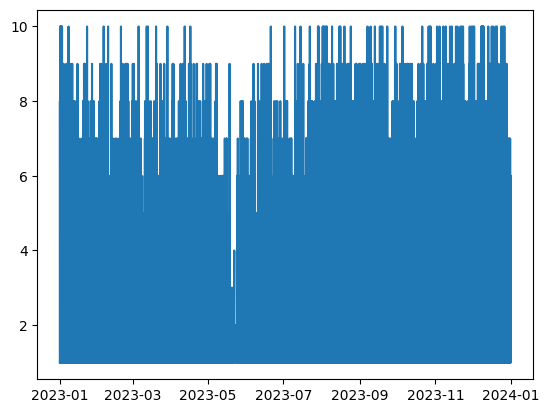

In [ ]:
plt.plot(date_counts.index, date_counts)

In [ ]:
df['job_posted_month'] = df['job_posted_date'].dt.month

In [ ]:
monthly_counts = df.job_posted_month.value_counts()

In [ ]:
monthly_counts = monthly_counts.sort_index()

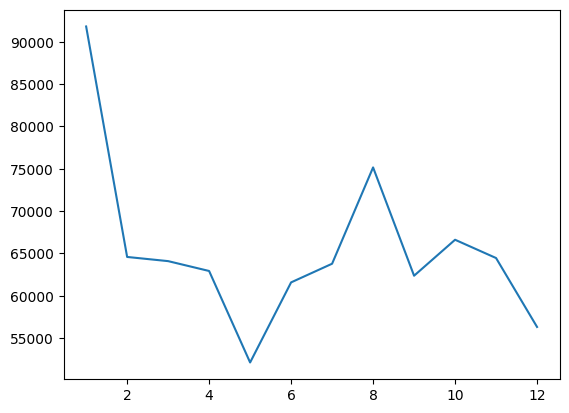

In [ ]:
plt.plot(monthly_counts.index, monthly_counts.values)

In [ ]:
job_counts = df.job_title_short.value_counts().sort_values(ascending = True)

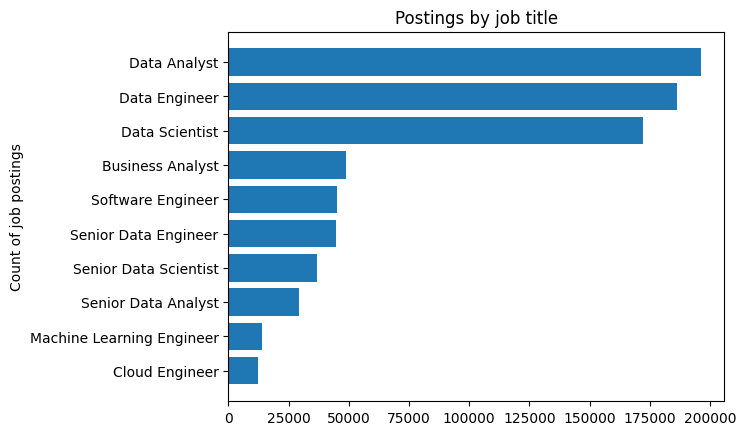

In [ ]:
plt.barh(job_counts.index, job_counts)
plt.title('Postings by job title')
plt.ylabel('Count of job postings')
plt.show()

<Axes: title={'center': 'Job Count by Job Title'}, xlabel='Job Title', ylabel='Number of Jobs'>

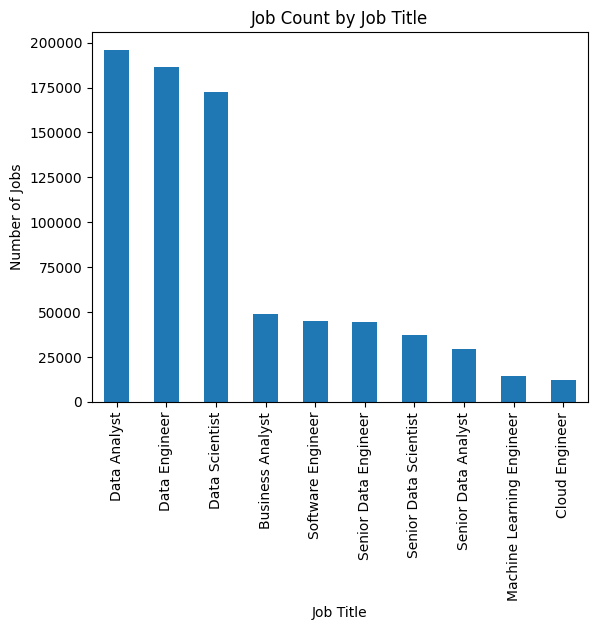

In [ ]:
df['job_title_short'].value_counts().plot(
    kind='bar',
    xlabel='Job Title',
    ylabel='Number of Jobs',
    title='Job Count by Job Title'
)

<Axes: title={'center': 'Job Count by Job Title'}, xlabel='Job Title', ylabel='Count'>

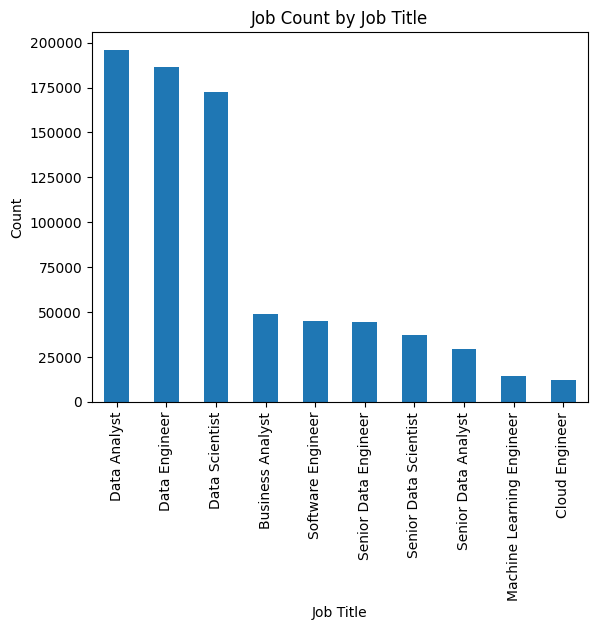

In [ ]:
df['job_title_short'].value_counts().plot(kind='bar', title='Job Count by Job Title', xlabel='Job Title', ylabel='Count')

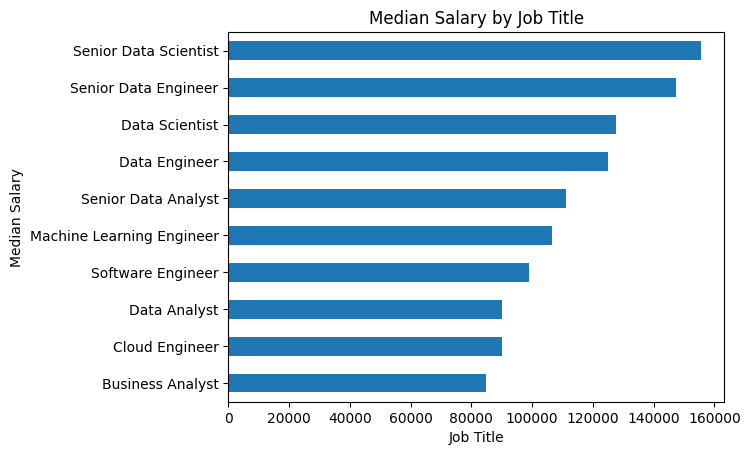

In [ ]:
df.groupby('job_title_short')['salary_year_avg'].median().sort_values(ascending = True).plot(kind='barh', title='Median Salary by Job Title', xlabel='Job Title', ylabel='Median Salary')
plt.show()